In [78]:
import math
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [110]:
# defining Value
# basically we're defining a class instead of using just float because we want each Value to store how it was computed, 
# not just its value. I need this for backpropagation. 


class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None #by default, the backward function does nothing. for each operation, the backward function is different, so it'll be defined separately inside each operation.
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):   
        out = Value(self.data + other.data, (self, other), '+')
        def _backward(): #I need a function that applies chain rule to find the grad of the inputs from the grad of the output.
            # imagine out is y, self is a and other is b. y = a+b, so dy/da =1. 
            # multiplying this by do/dy will give me do/da via chain rule
            self.grad += 1*out.grad
            other.grad += 1*out.grad
        out._backward = _backward #I need to store the backward function in the output so that I can call it later when I want to backpropagate through the graph.
        return out
    
    def __mul__(self, other):
        out = Value(self.data*other.data, (self, other), '*')
        def _backward():
            # if out is y, self is a and other is b. y = ab, so dy/da = b. 
            # multiplying this by do/dy will give me do/da via chain rule
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh') 
        #the (self, ) is a tuple representing the children of the operation. notice how it's just one child this time, which is n

        def _backward():
            # the derivative of y = tanh(x) is dy/dx = 1 - y^2.
            # here, since t = tanh(x), the local derivative is 1 - t^2
            # multiplying this by the 'global' derivative (do/dt) will give me do/dx via chain rule
            self.grad += out.grad * (1 - t**2)
        out._backward = _backward
        return out

    def backward(self):
        #this function makes sure a node only inserts itself 
        #into the topo list after all its children are there
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        #then, I need the reverse order for backprop
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
  

# example to play around
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'


print('c =',c)  
print('d =', d) 
print('children of d:', d._prev)
print('operation of e:', e._op)

    

c = Value(data=10.0)
d = Value(data=4.0)
children of d: {Value(data=10.0), Value(data=-6.0)}
operation of e: *


In [80]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [81]:
# function I can use to change different values by h and see how that affects L
def lol():
  
  h = 0.001
  
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L1 = L.data
  
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  b.data += h
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L2 = L.data
  
  print((L2 - L1)/h)
  
lol()

-3.9999999999995595


In [105]:
# applying the maths to a simple neural network model with values, weights, and biases

#values
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
#
#weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias
b = Value(6.8813735870195432, label='b')

#finding n (output). we'll do this step by step to have intermediate nodes that we can interact with

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'

n = x1w1x2w2 + b; n.label = 'n'


# creating an activation function (tanh) to compress n to a value between -1 and 1. 
# as a first step, I've gone up to the Value class and defined the tanh function using math.exp
# then, I n.tanh() should return the compressed version of n

o = n.tanh()

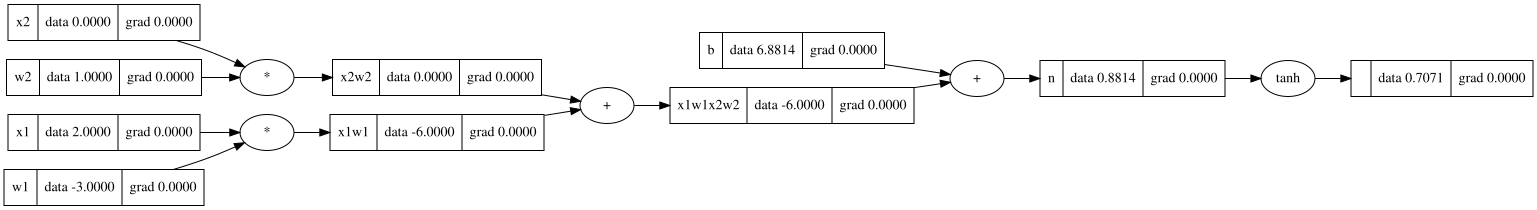

In [100]:
draw_dot(o)

In [101]:
# manual backpropagation example (no longer on the graph )

o.grad = 1.0 # cause it's the gradient of o with respect to itself. so rise/run is 1.

# backpropagating through tanh

# we know that o=tanh(n)
# the derivative of tanx is 1-tanx^2. when applied to our context, this means that do/dn = 1 - tanh(n)^2 = 1 - o^2. 

1 - o.data**2 # the output for this is 0.499999999999

#thus

n.grad = 0.5


# b and x1w1x2w2 have been added, so their gradients are equal to the gradient of n, which is 0.5.

b.grad = 0.5

x1w1x2w2.grad = 0.5

# same for x1w1 & x2w2

x1w1.grad = 0.5 
x2w2.grad = 0.5

# not same for x1 & x2 lol. here we apply chain rule w respect to o
# eg do/dx1 = do/dx1w1 * dx1w1/dx1 = x1w1.grad * w1.data

x1.grad = x1w1.grad * w1.data
x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data
w1.grad = x1w1.grad * x1.data




this was manual backpropagation. autograd when you do this **automatically:**


**first**, I'll go define a backward function in the Value class, which will be different for each operation.

### Backpropagation using _backward and then backward

In [102]:
o.grad = 1
o._backward() # as a result, when I run draw_dot(o) again, it shows 0.5 instead of 0 for the grad of n
n._backward() # this will extend the 0.5 to b & x1w1x2w2 cause n is the output of an addition
b._backward() #the output of this is None cause b is a leaf node
x1w1x2w2._backward() # again, this will extend the 0.5 (to x1w1 & x2w2) cause it's the output of an addition
x1w1._backward() #for x1 I'll get w1*0.5 = -3*0.5 = -1.5 via chain rule and vice versa for w1. same for x2 and w2
x2w2._backward()

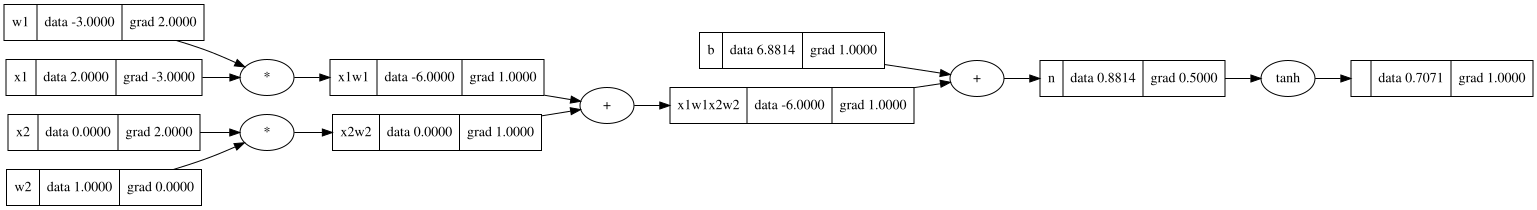

In [108]:
# I'm putting another draw function here for convenience
draw_dot(o)

In [107]:
#using the backward function to backprop the whole graph
o.backward()

bug fix check

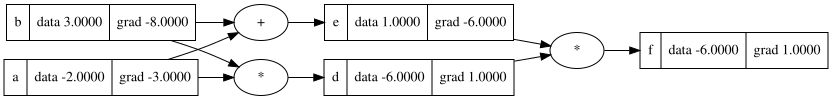

In [111]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b    ; d.label = 'd'
e = a + b    ; e.label = 'e'
f = d * e    ; f.label = 'f'

f.backward()

draw_dot(f)

## Notes

**Autograd** - Short for *automatic differentiation*. Automatically computes the gradient of the output of a program with respect to its inputs. 

**Chain Rule** - Intuitively -> if a car travels 2x faster than a bicycle, and the bicycle is 4x faster than walking human, how much faster does the car travel relative to the human? 2*4 = 8. So, in nerdier terms, if a variable x depends on a variable y, which depends on the variable z, then x depends on z too, through y. So dx/dz = dx/dy * dy/dz